# Opdracht 2: Voorspel verhuuraantallen

**Teamnaam: Bakabana pindasaus**

Aroetin Avanesi, aroetin 25103865

Moreo Rahiembaks, moreorahiembaks, 25107607

Kaylim Taai, kaylimtaai, 24093157

## Inhoudsopgave
1. Inleiding
2. Exploratieve Data Analyse
3. Time series feature engineering
4. Modelleren
5. Bevindingen
6. Conclusie en aanbevelingen
7. Referenties

## 1. Inleiding

CityBike verhuurt fietsen op verschillende locaties in een grote stad. Klanten kunnen op ieder moment van de dag een fiets huren, bijvoorbeeld om naar hun werk te gaan, om de stad te bekijken of gewoon om te recreëren. Als er te weinig fietsen staan, kan een klant geen fiets huren en loopt CityBike omzet mis. Als er juist te veel fietsen op één plek staan, worden fietsen en stallingsplaatsen niet goed benut.

De data lijkt sterk op de bekende Bike Sharing dataset van Capital Bikeshare in Washington D.C. (Fanaee-T & Gama, 2014). De kolommen, de periode (2011 en 2012) en de feestdagen komen daarmee overeen. Dat helpt ons om de genormaliseerde weerkolommen terug te rekenen naar echte eenheden (zie 2.2) en om opvallende momenten in de data te verklaren.

### 1.1 Probleemstelling

Ons team krijgt de vraag om op basis van historische gegevens te voorspellen **hoeveel fietsen er per uur worden verhuurd** (`cnt`). We trainen op de periode van 1 januari 2011 tot en met 30 november 2012 en voorspellen de periode van **1 tot en met 19 december 2012**.

Dit is een regressieprobleem met een tijdreeks. Dat heeft drie gevolgen voor onze aanpak:

1. **De volgorde in de tijd is belangrijk.** We mogen bij het valideren nooit trainen op data die na de validatieperiode ligt. Daarom gebruiken we geen gewone KFold maar een tijdgebaseerde cross-validation (hoofdstuk 4.1).
2. **We voorspellen 19 dagen vooruit.** Voor de testperiode kennen we `cnt` niet. Een feature als "het aantal verhuringen van een uur geleden" kunnen we daar dus niet gebruiken. Daar houden we rekening mee bij de feature engineering (hoofdstuk 3.3).
3. **De score is de RMSE.** Kaggle beoordeelt ons op de Root Mean Squared Error. De minimumeis is een RMSE van 80.

Het doel is een model dat CityBike helpt om de fietsen beter te verdelen, zodat klanten zo vaak mogelijk een fiets kunnen huren wanneer ze die nodig hebben.

## 2. Exploratieve Data Analyse

### 2.1 Data inladen

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Vaste kleuren, zodat dezelfde groep in iedere grafiek dezelfde kleur heeft
BLUE = "#257de0"
ORANGE = "#f47230"
sns.set_theme(style="whitegrid")

TARGET = "cnt"
WEATHER_COLS = ["temp", "atemp", "hum", "windspeed"]


class BikeData:
    """Laadt de datasets van de Kaggle competitie Voorspel verhuuraantallen."""

    def __init__(self, data_dir="voorspel-verhuuraantallen-2026"):
        # Map waarin de csv bestanden staan (in de GitHub repo)
        self.data_dir = Path(data_dir)
        self.train = None
        self.test = None
        self.submission = None

    def load(self):
        """Leest de drie csv bestanden in en zet date_hour om naar datetime."""
        self.train = pd.read_csv(self.data_dir / "train.csv",
                                 parse_dates=["date_hour"])
        self.test = pd.read_csv(self.data_dir / "test.csv",
                                parse_dates=["date_hour"])
        self.submission = pd.read_csv(
            self.data_dir / "sample_submission.csv"
        )
        return self

    def check_shapes(self):
        """Toont het aantal rijen en kolommen en de periode per dataset."""
        for name, df in [("train", self.train), ("test", self.test)]:
            print(f"{name:<6} {df.shape}  "
                  f"{df['date_hour'].min()} t/m {df['date_hour'].max()}")
        print(f"submission {self.submission.shape}")


data = BikeData().load()
data.check_shapes()
data.train.head()

train  (16637, 8)  2011-01-01 00:00:00 t/m 2012-11-30 23:00:00
test   (456, 7)  2012-12-01 00:00:00 t/m 2012-12-19 23:00:00
submission (456, 2)


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


### 2.2 Uitleg kolommen

De weerkolommen zijn genormaliseerd naar een waarde tussen 0 en 1. Volgens de beschrijving van de originele dataset (Fanaee-T, 2013) kun je ze zo terugrekenen naar echte eenheden. Dat gebruiken we in de grafieken, omdat "20 °C" makkelijker te lezen is dan "0,6".

| Kolom | Betekenis | Type | Terugrekenen |
|---|---|---|---|
| `date_hour` | Datum en uur van de meting | datetime | |
| `holiday` | 1 = officiële feestdag in Washington D.C., 0 = geen feestdag | binair | |
| `weathersit` | Weertype: 1 = helder, 2 = mist of bewolkt, 3 = lichte regen of sneeuw, 4 = zware regen, hagel of sneeuw | categorisch (geordend) | |
| `temp` | Temperatuur | continu | $t = temp \cdot 47 - 8$ (°C) |
| `atemp` | Gevoelstemperatuur | continu | $t = atemp \cdot 66 - 16$ (°C) |
| `hum` | Luchtvochtigheid | continu | $hum \cdot 100$ (%) |
| `windspeed` | Windsnelheid | continu | $windspeed \cdot 67$ (km/u) |
| `cnt` | **Target:** aantal verhuurde fietsen in dat uur | geheel getal | |

`weathersit` is een getal, maar eigenlijk een categorie met een volgorde: hoe hoger, hoe slechter het weer. Een model mag daarom ook rekenen met "hoger = slechter".

In [3]:
def describe_columns(df):
    """Datatype, aantal unieke waarden, bereik en voorbeelden per kolom."""
    return pd.DataFrame({
        "datatype": df.dtypes.astype(str),
        "uniek": df.nunique(),
        "minimum": df.min(),
        "maximum": df.max(),
        "voorbeeld": df.iloc[0],
    })


describe_columns(data.train)

,datatype,uniek,minimum,maximum,voorbeeld
date_hour,datetime64[us],16637,2011-01-01 00:00:00,2012-11-30 23:00:00,2011-01-01 00:00:00
holiday,int64,2,0,1,0
weathersit,int64,4,1,4,1
temp,float64,50,0.02,1.0,0.24
atemp,float64,65,0.0,1.0,0.2879
hum,float64,89,0.0,1.0,0.81
windspeed,float64,30,0.0,0.8507,0.0
cnt,int64,867,1,977,16


### 2.3 Datatypes en basisstatistieken

In [9]:
def show_overview(df):
    """Toont het formaat, ontbrekende waarden en dubbele rijen."""
    print(f"Rijen: {df.shape[0]}, kolommen: {df.shape[1]}")
    print(f"Ontbrekende waarden: {df.isna().sum().sum()}")
    print(f"Dubbele rijen: {df.duplicated().sum()}")


show_overview(data.train)
print(data.train.dtypes)
# Gemiddelde, spreiding, minimum, kwartielen en maximum
data.train.describe().round(3)

Rijen: 16637, kolommen: 8
Ontbrekende waarden: 0
Dubbele rijen: 0
date_hour     datetime64[us]
holiday                int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
cnt                    int64
dtype: object


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000,16637.000,16637.000,16637.000,16637.000,16637.000,16637.000
mean,2011-12-18 02:20:08.294764,0.029,1.416,0.505,0.483,0.625,0.190,190.477
min,2011-01-01 00:00:00,0.000,1.000,0.020,0.000,0.000,0.000,1.000
25%,2011-06-27 05:00:00,0.000,1.000,0.340,0.333,0.470,0.104,41.000
50%,2011-12-18 06:00:00,0.000,1.000,0.520,0.500,0.620,0.194,143.000
75%,2012-06-09 02:00:00,0.000,2.000,0.660,0.621,0.780,0.254,282.000
max,2012-11-30 23:00:00,1.000,4.000,1.000,1.000,1.000,0.851,977.000
std,NaN,0.167,0.637,0.192,0.172,0.193,0.122,182.027


In [ ]:
def count_values(df, columns):
    """Aantal en percentage per waarde voor categorische kolommen."""
    tables = []
    for col in columns:
        counts = df[col].value_counts().sort_index()
        tables.append(pd.DataFrame({
            "kolom": col,
            "waarde": counts.index,
            "aantal": counts.values,
            "percentage": (counts.values / len(df) * 100).round(2),
        }))
    return pd.concat(tables, ignore_index=True)


count_values(data.train, ["holiday", "weathersit"])

,kolom,waarde,aantal,percentage
0,holiday,0,16160,97.13
1,holiday,1,477,2.87
2,weathersit,1,11078,66.59
3,weathersit,2,4207,25.29
4,weathersit,3,1349,8.11
5,weathersit,4,3,0.02


Verwacht aantal uren: 16800
Ontbrekende uren:     163
Laagste waarde cnt:   1


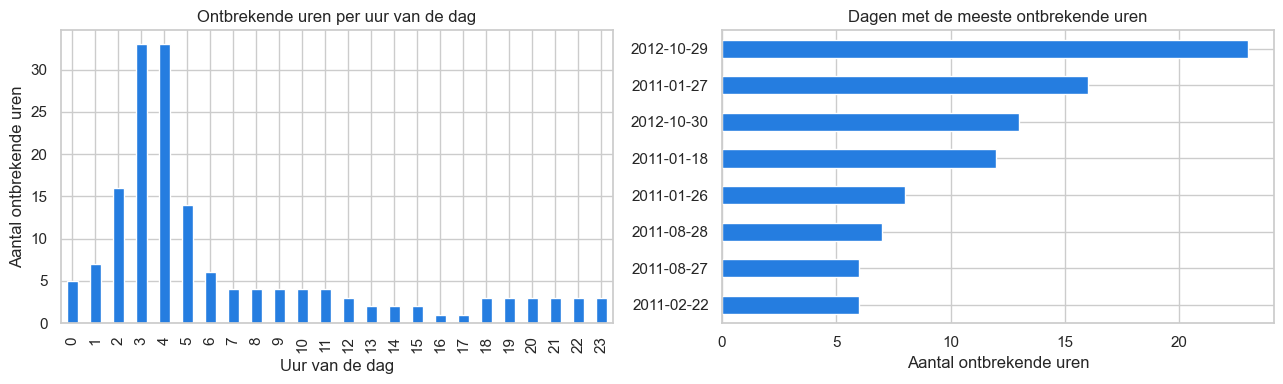

In [6]:
def find_missing_hours(df):
    """Geeft alle uren terug die in de reeks ontbreken."""
    full_range = pd.date_range(df["date_hour"].min(),
                               df["date_hour"].max(), freq="h")
    return full_range.difference(df["date_hour"])


missing = find_missing_hours(data.train)
print(f"Verwacht aantal uren: {len(missing) + len(data.train)}")
print(f"Ontbrekende uren:     {len(missing)}")
print(f"Laagste waarde cnt:   {data.train[TARGET].min()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(missing.hour).value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=BLUE)
axes[0].set_title("Ontbrekende uren per uur van de dag")
axes[0].set_xlabel("Uur van de dag")
axes[0].set_ylabel("Aantal ontbrekende uren")

pd.Series(missing.date).value_counts().head(8).sort_values().plot(
    kind="barh", ax=axes[1], color=BLUE)
axes[1].set_title("Dagen met de meeste ontbrekende uren")
axes[1].set_xlabel("Aantal ontbrekende uren")
plt.tight_layout()
plt.show()

In [7]:
def check_weather(df):
    """Telt verdachte waarden in de weerkolommen per dag."""
    temp_c = df["temp"] * 47 - 8
    atemp_c = df["atemp"] * 66 - 16
    checks = {
        "hum == 0": df["hum"] == 0,
        "windspeed == 0": df["windspeed"] == 0,
        "|temp - atemp| > 10 °C": (temp_c - atemp_c).abs() > 10,
    }
    for name, mask in checks.items():
        days = df.loc[mask, "date_hour"].dt.date.value_counts()
        print(f"{name:<24} {mask.sum():>5} uren, "
              f"vaakst op: {days.head(3).to_dict()}")


check_weather(data.train)

hum == 0                    22 uren, vaakst op: {datetime.date(2011, 3, 10): 22}
windspeed == 0            2072 uren, vaakst op: {datetime.date(2011, 10, 7): 20, datetime.date(2012, 11, 26): 16, datetime.date(2011, 12, 11): 15}
|temp - atemp| > 10 °C      37 uren, vaakst op: {datetime.date(2012, 8, 17): 24, datetime.date(2011, 7, 21): 7, datetime.date(2011, 7, 22): 6}


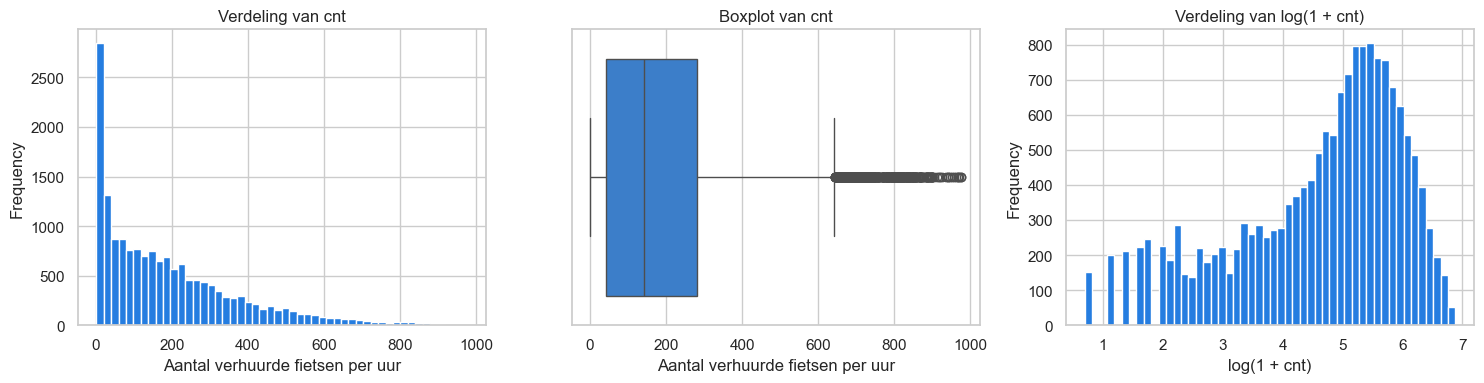

Scheefheid (skewness): 1.28
Outliers volgens de IQR-regel (cnt > 644): 486


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
data.train[TARGET].plot(kind="hist", bins=50, ax=axes[0], color=BLUE)
axes[0].set_title("Verdeling van cnt")
axes[0].set_xlabel("Aantal verhuurde fietsen per uur")

sns.boxplot(x=data.train[TARGET], ax=axes[1], color=BLUE)
axes[1].set_title("Boxplot van cnt")
axes[1].set_xlabel("Aantal verhuurde fietsen per uur")

np.log1p(data.train[TARGET]).plot(kind="hist", bins=50, ax=axes[2],
                                  color=BLUE)
axes[2].set_title("Verdeling van log(1 + cnt)")
axes[2].set_xlabel("log(1 + cnt)")
plt.tight_layout()
plt.show()

q1, q3 = data.train[TARGET].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Scheefheid (skewness): {data.train[TARGET].skew():.2f}")
print(f"Outliers volgens de IQR-regel (cnt > {upper:.0f}): "
      f"{(data.train[TARGET] > upper).sum()}")

**Wat hebben we gecontroleerd en wat zien we?**

We hebben gekeken naar de datatypes en basisstatistieken, de verdeling van de categorische kolommen, ontbrekende uren, verdachte waarden in het weer en de verdeling van `cnt`.

* **Datatypes.** De dataset heeft 16.637 rijen en 8 kolommen: `date_hour` (datetime), `holiday`, `weathersit` en `cnt` (gehele getallen) en vier weerkolommen (kommagetallen). Er zijn geen lege cellen en geen dubbele rijen of tijdstippen.
* **Er ontbreken 163 uren.** Er staan geen lege cellen in de data, maar een tijdreeks kan ook ontbrekende rijen hebben. Van 1 januari 2011 tot en met 30 november 2012 zouden er 16.800 uren moeten zijn. Opvallend is dat `cnt` nooit 0 is: het minimum is 1. Bijna alle ontbrekende uren liggen 's nachts, vooral tussen 2:00 en 5:00. Onze verklaring is dat een uur zonder één verhuring niet in de data is opgenomen. Een ontbrekend uur betekent dus waarschijnlijk **0 verhuringen**.
* **Twee grote gaten hebben een verklaring.** Op 29 en 30 oktober 2012 ontbreken 36 uren. Toen ging Capital Bikeshare vanwege orkaan Sandy dicht (Bates Area Civic Association, 2012). Ook in januari 2011 en op 27 en 28 augustus 2011 (orkaan Irene) ontbreken veel uren. Dit zijn uitzonderingen die het model niet hoeft te leren.
* **`weathersit` 4 komt maar 3 keer voor.** Van zo weinig voorbeelden kan een model niets leren (zie 2.7).
* **Fouten in de weerdata.** Een luchtvochtigheid van 0% kan niet, maar komt op 10 maart 2011 een hele dag voor. Op 17 augustus 2012 ligt `atemp` de hele dag meer dan 10 °C onder `temp`. Dat zijn meetfouten die we in 2.7 herstellen. Een windsnelheid van 0 komt 2.072 keer voor. Dat kan windstil zijn, maar ook een ontbrekende meting. Omdat we dat niet kunnen controleren, laten we deze waarden staan.
* **`cnt` is scheef naar rechts verdeeld** (skewness 1,28). De meeste uren hebben weinig verhuringen en er zijn een paar uren met heel veel. De IQR-regel noemt 486 drukke uren outliers, maar dat zijn gewoon de spitsuren. Die verwijderen we dus niet. Na een log-transformatie is de verdeling veel minder scheef. Dat proberen we bij het modelleren uit (hoofdstuk 4).

### 2.4 Tijdserie-elementen en patronen

### 2.5 Relaties tussen de variabelen en cnt

### 2.6 Belangrijkste bevindingen

### 2.7 Data opschonen

## 3. Time series feature engineering

### 3.1 Seizoenspatronen (Fourier analyse)

### 3.2 Trends

### 3.3 Cycli en autocorrelatie

### 3.4 Andere tijdsgebaseerde features

### 3.5 Invloed van de features en uiteindelijke keuze

## 4. Modelleren

### 4.1 Aanpak: RMSE, cross-validation en hyperparameter tuning

_4.2 t/m 4.6: modellen met time series features + reguliere features (minimaal 5 modellen)._

### 4.2 Lineaire regressie

#### Uitleg
_(wiskundige uitleg, met o.a. loss function en regularisatie)_
#### Resultaten

### 4.3 Ensemble model

#### Uitleg
_(wiskundige uitleg)_
#### Resultaten

### 4.4 Model 3 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.5 Model 4 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.6 Model 5 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.7 SARIMA(X)

#### Uitleg
#### Resultaten

### 4.8 Tweede tijdseriemodel (eigen keuze)

#### Uitleg
#### Resultaten

### 4.9 Hybride model

#### Uitleg
#### Resultaten

### 4.10 Voorspellingen voor Kaggle

## 5. Bevindingen

### 5.1 Samenvatting

### 5.2 Overzicht resultaten

| Model | Beste parameters | RMSE (CV) | RMSE Kaggle |
|---|---|---|---|
| Lineaire regressie | | | |
| Ensemble model | | | |
| Model 3 | | | |
| Model 4 | | | |
| Model 5 | | | |
| SARIMA(X) | | | |
| Tijdseriemodel 2 | | | |
| Hybride model | | | |

### 5.3 Welk model presteert het beste?

### 5.4 Kaggle-scores en verbeteringen

| Submission | Datum | Model / wijziging | RMSE Kaggle |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |

## 6. Conclusie en aanbevelingen

### 6.1 Welke features hebben de meeste invloed?

### 6.2 Aansluiting bij de EDA

### 6.3 Advies aan CityBike

### 6.4 Welk model adviseren wij en waarom?

## 7. Referenties